# Experimento: evaluar el modelo sin fugas de datos

Revisión de `entregable_Alan_McLure_Alarcon.ipynb`, que se conserva sin cambios como entrega original.

**Preguntas:**

1. ¿Cuánto error tiene de verdad el modelo original al predecir el precio real?
2. ¿Qué parte de sus métricas se debe a fugas de datos y al recorte del precio?
3. ¿Mejora el resultado con un `Pipeline` correcto, validación temporal y gradient boosting?

**Reglas del experimento:**

- La partición es temporal, como en el original: train hasta 2008, validación 2009 y test 2010.
- Todo lo que se aprende de los datos (codificaciones, imputaciones, hiperparámetros) se ajusta solo con datos anteriores a los que se evalúan.
- Los modelos se eligen con validación cruzada temporal. El test se usa una sola vez, con el modelo ya elegido, y con el modelo original como comparación.
- El error se mide siempre en dólares contra `SalePrice` sin recortar, salvo donde se indica.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn import metrics
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}' if abs(v) < 10 else f'{v:,.0f}')
SEED = 42
COLOR = '#2a78b4'
INK_MUTED = '#6b7280'
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.2.6


## 1. Datos y alcance

Se mantiene el alcance del original: ventas normales (`SaleType == 'WD'`, `SaleCondition == 'Normal'`) de casas de hasta 4000 pies cuadrados. Son decisiones sobre qué problema se resuelve, no se aprenden del precio, y por eso pueden aplicarse antes de dividir.

Los datos de 2010 no cubren el año completo, algo que hay que tener en cuenta al leer el test.

In [2]:
raw = pd.read_csv('data/house-price-data.csv')

en_alcance = (raw['GrLivArea'] <= 4000) & (raw['SaleType'] == 'WD') & (raw['SaleCondition'] == 'Normal')
data = raw[en_alcance].sort_values(['YrSold', 'MoSold', 'Id']).reset_index(drop=True)

train = data[data['YrSold'] <= 2008]
validation = data[data['YrSold'] == 2009]
test = data[data['YrSold'] == 2010]
desarrollo = data[data['YrSold'] <= 2009]  # train + validación, ordenado por fecha

print(f'Filas: {len(raw)} originales, {len(data)} en alcance')
print(f'Train {len(train)} | Validación {len(validation)} | Test {len(test)}')
print(f"Último mes de venta en 2010: {test['MoSold'].max()}")

Filas: 1460 originales, 1159 en alcance
Train 732 | Validación 277 | Test 150
Último mes de venta en 2010: 7


## 2. Reproducir el modelo original

`preparacion_original` repite las transformaciones del notebook original y en el mismo orden. Si los números coinciden con los de la entrega, las comparaciones posteriores son válidas.

Contiene dos problemas que ya se ven al leerla:

- **Fuga de datos:** los percentiles y las medias por categoría se calculan con todas las filas, incluidas las de validación y test. El propio notebook ya señalaba este riesgo en la codificación por precio medio.
- **Objetivo recortado:** `SalePrice` se limita al rango de los percentiles 5 y 95 también en validación y test. El modelo se evalúa contra un precio modificado, y los errores de las casas más caras y más baratas quedan ocultos.

In [3]:
VARIABLES_ORIGINALES = ['OverallQual', 'GrLivArea', 'YearBuilt', 'Neighborhood', 'TotalArea',
                        'TotalBathrooms', 'Renovated', 'MSSubClass', 'MSZoning']


def codificar_por_precio_medio(df, columna):
    orden = (df.groupby(columna, observed=False)['SalePrice'].mean()
             .sort_values(ascending=False).index.tolist())
    df[columna] = OrdinalEncoder(categories=[orden]).fit_transform(df[[columna]])


def preparacion_original(df):
    d = df.loc[df['GrLivArea'] <= 4000].copy()
    d['YearBuilt'] = d['YearBuilt'].clip(lower=1900)
    d['GarageArea'] = d['GarageArea'].clip(upper=d['GarageArea'].quantile(0.99))
    codificar_por_precio_medio(d, 'Neighborhood')
    d = d[(d['SaleType'] == 'WD') & (d['SaleCondition'] == 'Normal')].copy()
    d['SalePrice_Real'] = d['SalePrice'].astype(float)
    # round + astype(int) replica el downcasting a entero que hacía pandas en la entrega original.
    d['SalePrice'] = (d['SalePrice_Real'].clip(d['SalePrice_Real'].quantile(0.05),
                                               d['SalePrice_Real'].quantile(0.95)).round().astype(int))
    d['MSSubClass'] = d['MSSubClass'].astype(str)
    codificar_por_precio_medio(d, 'MSSubClass')
    codificar_por_precio_medio(d, 'MSZoning')
    d['TotalArea'] = (d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF'] + d['GarageArea']).clip(1200, 5000)
    d['Renovated'] = (d['YearRemodAdd'] > d['YearBuilt']).astype(int)
    d['TotalBathrooms'] = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    return d[d['TotalBathrooms'] != 5]


def dividir_original(d):
    return d[d['YrSold'] <= 2008], d[d['YrSold'] == 2009], d[d['YrSold'] == 2010]


def resumen(nombre, y_real, pred):
    return {'modelo': nombre,
            'filas': len(y_real),
            'MAE': metrics.mean_absolute_error(y_real, pred),
            'MedAE': metrics.median_absolute_error(y_real, pred),
            'RMSE': metrics.root_mean_squared_error(y_real, pred),
            'R2': metrics.r2_score(y_real, pred)}


orig = preparacion_original(raw)
o_train, o_val, o_test = dividir_original(orig)

lr_original = LinearRegression().fit(o_train[VARIABLES_ORIGINALES], o_train['SalePrice'])
rf_original = RandomForestRegressor(n_estimators=100, random_state=SEED).fit(
    o_train[VARIABLES_ORIGINALES], o_train['SalePrice'])

pd.DataFrame([
    resumen('Regresión lineal, validación', o_val['SalePrice'], lr_original.predict(o_val[VARIABLES_ORIGINALES])),
    resumen('Regresión lineal, test', o_test['SalePrice'], lr_original.predict(o_test[VARIABLES_ORIGINALES])),
    resumen('Random forest, validación', o_val['SalePrice'], rf_original.predict(o_val[VARIABLES_ORIGINALES])),
    resumen('Random forest, test', o_test['SalePrice'], rf_original.predict(o_test[VARIABLES_ORIGINALES])),
]).set_index('modelo')

,filas,MAE,MedAE,RMSE,R2
modelo,,,,,
"Regresión lineal, validación",277,"16,562","12,952","21,299",0.878
"Regresión lineal, test",150,"15,912","11,887","20,911",0.870
"Random forest, validación",277,"15,450","11,821","20,507",0.887
"Random forest, test",150,"14,064","9,849","19,219",0.890


In [4]:
# La entrega original publicó estas métricas (MAE y R2).
ENTREGA = {'lr_val': (16561.66, 0.8780), 'lr_test': (15912.43, 0.8698),
           'rf_val': (15450.22, 0.8869), 'rf_test': (14064.10, 0.8901)}
pares = {'lr_val': (lr_original, o_val), 'lr_test': (lr_original, o_test),
         'rf_val': (rf_original, o_val), 'rf_test': (rf_original, o_test)}

for clave, (modelo, parte) in pares.items():
    pred = modelo.predict(parte[VARIABLES_ORIGINALES])
    assert abs(metrics.mean_absolute_error(parte['SalePrice'], pred) - ENTREGA[clave][0]) < 1, clave
    assert abs(metrics.r2_score(parte['SalePrice'], pred) - ENTREGA[clave][1]) < 0.001, clave
print('Reproducción correcta: las métricas coinciden con la entrega original.')

Reproducción correcta: las métricas coinciden con la entrega original.


## 3. Un `Pipeline` que no puede filtrar datos

`crear_variables` calcula las mismas variables derivadas fila a fila, sin aprender nada de los datos. Las categorías se codifican con `TargetEncoder` dentro del `Pipeline`, de modo que sus medias salen solo del conjunto con el que se ajusta y, durante el ajuste, de particiones cruzadas internas.

También se añade un conjunto ampliado: las variables de calidad que el notebook original analizó pero no usó en el modelo final, más otras características de la casa como `GarageCars`, `LotArea` y `OverallCond`.

In [5]:
CALIDAD = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1}
CATEGORICAS = ['Neighborhood', 'MSSubClass', 'MSZoning']
NUMERICAS_BASE = ['OverallQual', 'GrLivArea', 'YearBuilt', 'TotalArea', 'TotalBathrooms', 'Renovated']
NUMERICAS_AMPLIADAS = NUMERICAS_BASE + ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu', 'GarageCars',
                                        'LotArea', 'OverallCond', 'YearRemodAdd', 'Fireplaces']


def crear_variables(df):
    d = df.copy()
    d['TotalArea'] = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF'] + d['GarageArea']
    d['Renovated'] = (d['YearRemodAdd'] > d['YearBuilt']).astype(int)
    d['TotalBathrooms'] = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    for columna in ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']:
        # El diccionario de datos indica que un valor ausente significa "no tiene": equivale a 0.
        d[columna] = d[columna].map(CALIDAD).fillna(0)
    d['MSSubClass'] = d['MSSubClass'].astype(str)
    return d


def construir_pipeline(numericas, modelo, escalar=False):
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('escalar', StandardScaler()))
    preprocesado = ColumnTransformer([
        ('num', Pipeline(pasos_num), numericas),
        ('cat', TargetEncoder(target_type='continuous', random_state=SEED), CATEGORICAS),
    ], verbose_feature_names_out=False)
    return Pipeline([('variables', FunctionTransformer(crear_variables)),
                     ('preprocesado', preprocesado),
                     ('modelo', modelo)])


def con_log(pipeline):
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)


X = lambda df: df.drop(columns='SalePrice')
y = lambda df: df['SalePrice'].astype(float)

### Comprobación: ¿el test influye en el modelo?

Si multiplicamos por 3 los precios de 2010, las predicciones sobre 2010 no deberían cambiar: un modelo real no conoce el precio de lo que va a predecir. Es una prueba directa de la fuga.

In [6]:
alterado = raw.copy()
alterado.loc[alterado['YrSold'] == 2010, 'SalePrice'] *= 3


def predicciones_original(df):
    tr, _, te = dividir_original(preparacion_original(df))
    return LinearRegression().fit(tr[VARIABLES_ORIGINALES], tr['SalePrice']).predict(te[VARIABLES_ORIGINALES])


def predicciones_pipeline(df):
    d = df[(df['GrLivArea'] <= 4000) & (df['SaleType'] == 'WD') & (df['SaleCondition'] == 'Normal')]
    d = d.sort_values(['YrSold', 'MoSold', 'Id'])
    tr, te = d[d['YrSold'] <= 2009], d[d['YrSold'] == 2010]
    return construir_pipeline(NUMERICAS_BASE, LinearRegression()).fit(X(tr), y(tr)).predict(X(te))


cambio_original = np.abs(predicciones_original(raw) - predicciones_original(alterado)).mean()
cambio_pipeline = np.abs(predicciones_pipeline(raw) - predicciones_pipeline(alterado)).mean()

print(f'Original: las predicciones de 2010 cambian de media ${cambio_original:,.0f}')
print(f'Pipeline: las predicciones de 2010 cambian de media ${cambio_pipeline:,.2f}')
assert cambio_original > 100, 'Se esperaba detectar la fuga del flujo original'
assert cambio_pipeline == 0, 'El pipeline no debe depender de los precios del test'

Original: las predicciones de 2010 cambian de media $6,024
Pipeline: las predicciones de 2010 cambian de media $0.00


## 4. ¿De dónde sale la diferencia?

Regresión lineal con las variables originales, sobre el conjunto de validación (2009), para no tocar el test. A→B solo cambia contra qué precio se mide. B→C cambia varias cosas a la vez: quita la fuga, sustituye la codificación ordinal por `TargetEncoder`, quita los recortes de variables y conserva una fila que el original eliminaba. C→D y D→E cambian solo cómo se trata el precio al entrenar.

La columna `MAE rango medio` mide solo casas de entre 90.000 y 307.200 dólares, los límites del recorte original. El notebook original optimizaba el modelo para ese rango, de modo que es la lectura más justa para el modelo recortado.

In [7]:
LIM_BAJO, LIM_ALTO = 90_000, 307_200


def fila_paso(nombre, y_eval, y_real, pred):
    rango = y_real.between(LIM_BAJO, LIM_ALTO)
    return {'paso': nombre,
            'MAE': metrics.mean_absolute_error(y_eval, pred),
            'R2': metrics.r2_score(y_eval, pred),
            'MAE rango medio': metrics.mean_absolute_error(y_eval[rango], pred[rango])}


pred_o = lr_original.predict(o_val[VARIABLES_ORIGINALES])
y_tr, y_va = y(train), y(validation)
recorte = y_tr.clip(y_tr.quantile(0.05), y_tr.quantile(0.95))

p_recorte = construir_pipeline(NUMERICAS_BASE, LinearRegression()).fit(X(train), recorte).predict(X(validation))
p_sin_recorte = construir_pipeline(NUMERICAS_BASE, LinearRegression()).fit(X(train), y_tr).predict(X(validation))
p_log = con_log(construir_pipeline(NUMERICAS_BASE, LinearRegression())).fit(X(train), y_tr).predict(X(validation))

pasos = pd.DataFrame([
    fila_paso('A. Entrega: con fuga, evaluado contra precio recortado', o_val['SalePrice'], o_val['SalePrice_Real'], pred_o),
    fila_paso('B. Con fuga, evaluado contra precio real', o_val['SalePrice_Real'], o_val['SalePrice_Real'], pred_o),
    fila_paso('C. Sin fuga, entrenado con precio recortado', y_va, y_va, p_recorte),
    fila_paso('D. Sin fuga, entrenado con precio real', y_va, y_va, p_sin_recorte),
    fila_paso('E. Sin fuga, entrenado con log(precio)', y_va, y_va, p_log),
]).set_index('paso')
pasos

,MAE,R2,MAE rango medio
paso,,,
"A. Entrega: con fuga, evaluado contra precio recortado","16,562",0.878,"15,493"
"B. Con fuga, evaluado contra precio real","19,882",0.820,"15,493"
"C. Sin fuga, entrenado con precio recortado","19,160",0.832,"14,761"
"D. Sin fuga, entrenado con precio real","19,564",0.859,"16,751"
"E. Sin fuga, entrenado con log(precio)","15,669",0.902,"14,608"


## 5. Comparar modelos con validación cruzada temporal

`TimeSeriesSplit` entrena siempre con el pasado y evalúa con el futuro, igual que se usaría el modelo en la práctica. Como el preprocesado está dentro del `Pipeline`, se vuelve a ajustar en cada partición.

Solo se usan datos de 2006 a 2009: el test sigue sin tocarse.

In [8]:
cv = TimeSeriesSplit(n_splits=4)


def candidatos(numericas):
    return {
        'Regresión lineal': construir_pipeline(numericas, LinearRegression()),
        'Regresión lineal + log': con_log(construir_pipeline(numericas, LinearRegression())),
        'Ridge + log': con_log(construir_pipeline(numericas, Ridge(alpha=1.0), escalar=True)),
        'Random forest': construir_pipeline(numericas, RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
        'Gradient boosting': construir_pipeline(numericas, HistGradientBoostingRegressor(random_state=SEED)),
        'Gradient boosting + log': con_log(construir_pipeline(numericas, HistGradientBoostingRegressor(random_state=SEED))),
    }


filas, modelos = [], {}
for conjunto, numericas in [('originales', NUMERICAS_BASE), ('ampliadas', NUMERICAS_AMPLIADAS)]:
    for nombre, modelo in candidatos(numericas).items():
        puntos = -cross_val_score(modelo, X(desarrollo), y(desarrollo), cv=cv, scoring='neg_mean_absolute_error')
        clave = f'{nombre} ({conjunto})'
        modelos[clave] = modelo
        filas.append({'modelo': clave, 'MAE CV': puntos.mean(), 'desviación': puntos.std()})

comparacion = pd.DataFrame(filas).set_index('modelo').sort_values('MAE CV')
comparacion

,MAE CV,desviación
modelo,,
Regresión lineal + log (ampliadas),"14,889","2,303"
Ridge + log (ampliadas),"14,955","2,545"
Gradient boosting + log (ampliadas),"15,176",935
Ridge + log (originales),"15,529",925
Regresión lineal + log (originales),"15,589","1,014"
Gradient boosting (ampliadas),"16,009","1,493"
Random forest (ampliadas),"16,313",596
Gradient boosting + log (originales),"17,307",575
Random forest (originales),"17,408",712


## 6. Buscar hiperparámetros

Búsqueda aleatoria sobre gradient boosting con las variables ampliadas y el objetivo en logaritmo, con la misma validación temporal.

In [9]:
base_gb = con_log(construir_pipeline(NUMERICAS_AMPLIADAS, HistGradientBoostingRegressor(random_state=SEED)))
espacio = {
    'regressor__modelo__learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
    'regressor__modelo__max_iter': [150, 300, 500, 800],
    'regressor__modelo__max_leaf_nodes': [4, 6, 8, 12, 16, 31],
    'regressor__modelo__min_samples_leaf': [5, 10, 20, 30],
    'regressor__modelo__l2_regularization': [0.0, 0.1, 1.0, 5.0],
}
busqueda = RandomizedSearchCV(base_gb, espacio, n_iter=40, cv=cv, scoring='neg_mean_absolute_error',
                              random_state=SEED, n_jobs=-1).fit(X(desarrollo), y(desarrollo))

mae_busqueda = -busqueda.best_score_
std_busqueda = busqueda.cv_results_['std_test_score'][busqueda.best_index_]
modelos['Gradient boosting + log, ajustado (ampliadas)'] = busqueda.best_estimator_
comparacion.loc['Gradient boosting + log, ajustado (ampliadas)'] = [mae_busqueda, std_busqueda]
comparacion = comparacion.sort_values('MAE CV')

print({k.split('__')[-1]: v for k, v in busqueda.best_params_.items()})
comparacion.head(6)

{'min_samples_leaf': 5, 'max_leaf_nodes': 6, 'max_iter': 500, 'learning_rate': 0.05, 'l2_regularization': 1.0}


,MAE CV,desviación
modelo,,
"Gradient boosting + log, ajustado (ampliadas)","14,128",639
Regresión lineal + log (ampliadas),"14,889","2,303"
Ridge + log (ampliadas),"14,955","2,545"
Gradient boosting + log (ampliadas),"15,176",935
Ridge + log (originales),"15,529",925
Regresión lineal + log (originales),"15,589","1,014"


## 7. Evaluación final en test

Se elige el modelo con menor MAE en validación cruzada, se reentrena con 2006-2009 y se evalúa una sola vez en 2010.

**Comparación justa:** el random forest original se reentrena con 2006-2009, la misma ventana que el modelo final, conservando su preparación con fuga. Todos se evalúan contra el precio real y sobre las mismas casas. Con solo unas 150 ventas, una diferencia pequeña puede ser ruido, así que se añade un intervalo de confianza por bootstrap.

In [10]:
elegido = comparacion.index[0]
print('Modelo elegido por validación cruzada:', elegido)

final = clone(modelos[elegido]).fit(X(desarrollo), y(desarrollo))
pred_final = pd.Series(final.predict(X(test)), index=test['Id'])
real = test.set_index('Id')['SalePrice'].astype(float)

pred_rf = pd.Series(rf_original.predict(o_test[VARIABLES_ORIGINALES]), index=o_test['Id'])
pred_lr = pd.Series(lr_original.predict(o_test[VARIABLES_ORIGINALES]), index=o_test['Id'])

o_desarrollo = orig[orig['YrSold'] <= 2009]
rf_misma_ventana = RandomForestRegressor(n_estimators=100, random_state=SEED).fit(
    o_desarrollo[VARIABLES_ORIGINALES], o_desarrollo['SalePrice'])
pred_rf_vent = pd.Series(rf_misma_ventana.predict(o_test[VARIABLES_ORIGINALES]), index=o_test['Id'])

comunes = real.index.intersection(pred_rf.index)
media_train = y(desarrollo).mean()
filas = [
    resumen('Referencia: media de 2006-2009', real[comunes], np.full(len(comunes), media_train)),
    resumen('Regresión lineal original', real[comunes], pred_lr[comunes]),
    resumen('Random forest original (2006-2008)', real[comunes], pred_rf[comunes]),
    resumen('Random forest original (2006-2009)', real[comunes], pred_rf_vent[comunes]),
    resumen(elegido, real[comunes], pred_final[comunes]),
]
resultado = pd.DataFrame(filas).set_index('modelo')
rango = real[comunes].between(LIM_BAJO, LIM_ALTO)
resultado['MAE rango medio'] = [
    metrics.mean_absolute_error(real[comunes][rango], np.full(rango.sum(), media_train)),
    metrics.mean_absolute_error(real[comunes][rango], pred_lr[comunes][rango]),
    metrics.mean_absolute_error(real[comunes][rango], pred_rf[comunes][rango]),
    metrics.mean_absolute_error(real[comunes][rango], pred_rf_vent[comunes][rango]),
    metrics.mean_absolute_error(real[comunes][rango], pred_final[comunes][rango]),
]
resultado

Modelo elegido por validación cruzada: Gradient boosting + log, ajustado (ampliadas)


,filas,MAE,MedAE,RMSE,R2,MAE rango medio
modelo,,,,,,
Referencia: media de 2006-2009,150,"51,875","39,871","70,155",-0.000,"39,570"
Regresión lineal original,150,"19,296","12,713","31,589",0.797,"15,409"
Random forest original (2006-2008),150,"18,389","11,937","30,662",0.809,"13,959"
Random forest original (2006-2009),150,"18,196","12,225","30,544",0.810,"13,769"
"Gradient boosting + log, ajustado (ampliadas)",150,"13,330","9,934","19,264",0.925,"12,471"


In [11]:
rng = np.random.default_rng(SEED)
error_final = np.abs(real[comunes] - pred_final[comunes]).to_numpy()
error_rf = np.abs(real[comunes] - pred_rf_vent[comunes]).to_numpy()

muestras = rng.integers(0, len(comunes), size=(10_000, len(comunes)))
mae_final_b = error_final[muestras].mean(axis=1)
dif_b = (error_rf[muestras] - error_final[muestras]).mean(axis=1)

print(f'MAE del modelo final: ${error_final.mean():,.0f} '
      f'(IC 95%: ${np.percentile(mae_final_b, 2.5):,.0f} a ${np.percentile(mae_final_b, 97.5):,.0f})')
print(f'Mejora frente al random forest original con la misma ventana: ${dif_b.mean():,.0f} '
      f'(IC 95%: ${np.percentile(dif_b, 2.5):,.0f} a ${np.percentile(dif_b, 97.5):,.0f})')
print('El intervalo de la mejora', 'no incluye 0.' if np.percentile(dif_b, 2.5) > 0 else 'incluye 0: la diferencia podría ser ruido.')

MAE del modelo final: $13,330 (IC 95%: $11,201 a $15,691)
Mejora frente al random forest original con la misma ventana: $4,859 (IC 95%: $2,241 a $7,991)
El intervalo de la mejora no incluye 0.


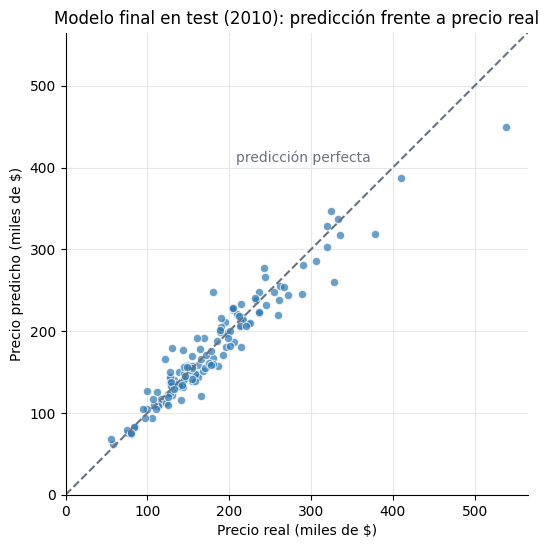

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(real[comunes] / 1000, pred_final[comunes] / 1000, s=36, color=COLOR, alpha=0.7,
           edgecolor='white', linewidth=0.8)
limites = [0, max(real[comunes].max(), pred_final[comunes].max()) / 1000 * 1.05]
ax.plot(limites, limites, color=INK_MUTED, linewidth=1.5, linestyle='--')
ax.text(limites[1] * 0.66, limites[1] * 0.72, 'predicción perfecta', ha='right', color=INK_MUTED, fontsize=10)
ax.set(xlim=limites, ylim=limites, xlabel='Precio real (miles de $)', ylabel='Precio predicho (miles de $)',
       title='Modelo final en test (2010): predicción frente a precio real')
ax.set_aspect('equal')
ax.grid(color='#e5e7eb', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 8. ¿Qué variables usa el modelo?

Importancia por permutación en test: cuánto empeora el MAE, en dólares, si se desordena una variable. Mide lo que usa este modelo, no una relación causal con el precio. Si dos variables están muy relacionadas, como las superficies, se reparten la importancia.

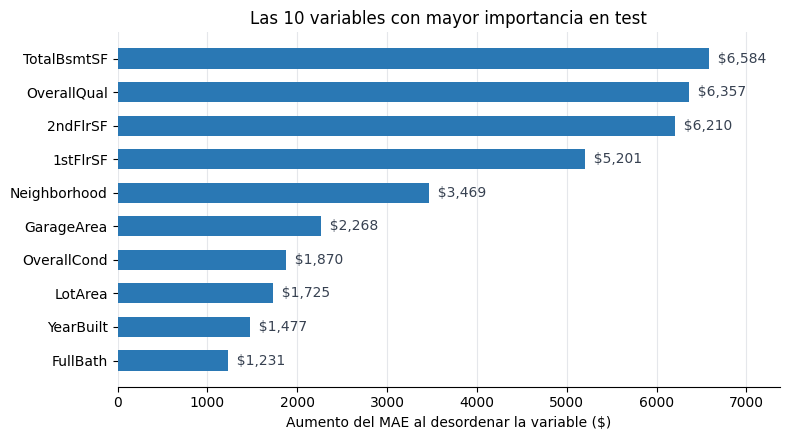

In [13]:
columnas = [c for c in X(test).columns]
imp = permutation_importance(final, X(test), y(test), scoring='neg_mean_absolute_error',
                             n_repeats=30, random_state=SEED)
importancia = pd.Series(imp.importances_mean, index=columnas)
top = importancia[importancia.abs() > 0].sort_values(ascending=False).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=COLOR, height=0.6)
for nombre, valor in top.items():
    ax.text(valor, nombre, f'  ${valor:,.0f}', va='center', fontsize=10, color='#374151')
ax.set(xlabel='Aumento del MAE al desordenar la variable ($)', title='Las 10 variables con mayor importancia en test')
ax.margins(x=0.12)
ax.grid(axis='x', color='#e5e7eb', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Conclusiones

| Modelo en test (2010) | Se mide contra | MAE | R² |
| --- | --- | --- | --- |
| Random forest de la entrega | Precio recortado | $14.064 | 0,890 |
| El mismo modelo | Precio real | $18.389 | 0,809 |
| El mismo modelo, entrenado con 2006-2009 | Precio real | $18.196 | 0,810 |
| Gradient boosting + log, ajustado | Precio real | **$13.330** | **0,925** |

1. **La métrica original era optimista, sobre todo por el recorte.** Medir contra el precio real sube el MAE en validación de $16.562 a $19.882 con la misma regresión lineal.
2. **La fuga de datos existe, pero aquí pesa poco en el error.** Las predicciones originales de 2010 cambian de media $6.024 si se alteran los precios de 2010, así que la fuga es real. Aun así, el flujo sin fuga no empeora en validación ($19.160 frente a $19.882). Ese paso cambia varias cosas a la vez, de modo que no aísla el efecto exacto de la fuga. Corregirla sigue siendo necesario, porque el modelo no debe depender de datos futuros.
3. **El cambio más rentable fue predecir el logaritmo del precio.** Con el mismo modelo lineal, el MAE en validación baja de $19.564 a $15.669. El error en los precios suele ser proporcional, no absoluto, y el logaritmo refleja esa forma.
4. **El modelo final mejora al original con un margen claro, sobre todo en los extremos.** La mejora es de $4.859 de MAE con la misma ventana de entrenamiento (IC 95%: $2.241 a $7.991). En el rango medio la mejora es menor: de $13.769 a $12.471.

**Límites:**

- El test tiene 150 ventas de enero a julio de 2010 en una sola ciudad: el intervalo del MAE final va de $11.201 a $15.691.
- El alcance excluye ventas no normales y casas de más de 4000 pies cuadrados: el modelo no sirve para ellas.
- La importancia de variables describe este modelo, no causas del precio.
- Los números pueden variar ligeramente con otras versiones de las librerías, ya que `requirements.txt` no fija versiones.